# 03 · Data preparation, features and interventions

<a id="11-SETUP"></a>
<a id="SETUP"></a>
### `SETUP` · Setup: component environment and immutable evidence

In [1]:
# SETUP
from pathlib import Path
import sys
WORKSPACE = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'source/bpdr_input').is_dir())
sys.path.insert(0, str(WORKSPACE / 'source'))
from bpdr_input.reporting.notebook_setup import prepare, load_catalogs, show
globals().update(prepare(WORKSPACE))
show(pd.DataFrame([{'check': 'Saved model and evidence identities', 'result': 'PASS',
                    'recorded_run': RUN.name}]))


,check,result,recorded_run
0,Saved model and evidence identities,PASS,b4c64c3b861a48c494c092458716b4fc


<a id="11-CONTEXT"></a>
<a id="CONTEXT"></a>
### `CONTEXT` · Load local split catalogs and common helper names

In [2]:
#CONTEXT
globals().update(load_catalogs(RUN, MANIFEST))
show(pd.DataFrame([
    dict(split=s, recordings=len(SOURCE_RECORDS[s]), singers=len(groups[s]),
         intervention_attempts=len(PAIRS[s])) for s in SPLITS
]))


,split,recordings,singers,intervention_attempts
0,train,16,8,64
1,calibration,4,2,16
2,pilot_evaluation,4,2,16


These are the **VocalSet recovery** catalogs: 24 recordings, 12 assigned singers and 96 intervention attempts, including exclusions. They are not the historical Transformer training set. Full source, split and feature details are shown in notebook 03.

<a id="DATA-SOURCES"></a>
### `DATA-SOURCES` · Official sources, hashes and archive CRCs

In [3]:
# DATA-SOURCES
source_rows = []
for r in MANIFEST['records']:
    path = Path(r['path']).resolve()
    info = sf.info(path)
    audio, rate = sf.read(path, dtype='float32')
    source_rows.append(dict(split=r['split'], singer=r['singer_id'], 
                            vowel=r['vowel'], source_file=path.name, 
                            duration_seconds=info.duration, 
                            rate_Hz=rate, channels=info.channels, 
                            finite=bool(np.isfinite(audio).all()), 
                            peak=float(np.max(np.abs(audio))), 
                            RMS=float(np.sqrt(np.mean(audio.astype(np.float64) ** 2))), 
                            clipped_fraction=float(np.mean(np.abs(audio) >= 0.999)), sha256=r['sha256']))
SOURCES = pd.DataFrame(source_rows)

show(SOURCES[['split', 'singer', 'vowel', 'duration_seconds', 'rate_Hz', 'finite']].round(5))

,split,singer,vowel,duration_seconds,rate_Hz,finite
0,train,female1,a,11.8226,44100,True
1,train,female1,e,10.6404,44100,True
2,train,female2,a,11.9721,44100,True
3,train,female2,e,10.5489,44100,True
4,train,female3,a,11.1270,44100,True
5,train,female3,e,10.5644,44100,True
6,train,female4,a,11.1522,44100,True
7,train,female4,e,12.0355,44100,True
8,calibration,female5,a,12.8132,44100,True
9,calibration,female5,e,15.7125,44100,True


 Rows are original VocalSet recordings, not independent intervention variants. Source hashes, archive-entry CRCs and decoded metadata are checked; the complete archive was not downloaded or MD5-verified.

<a id="DATA-CLEAN"></a>
### `DATA-CLEAN` · Cleaning, rates and working-copy verification

In [4]:
# DATA-CLEAN
SPLITS = ['train', 'calibration', 'pilot_evaluation']
SOURCE_RECORDS = {s: read_json(RUN / (s + '_sources.json')) for s in SPLITS}
PAIRS = {s: read_json(RUN / (s + '_pairs.json')) for s in SPLITS}
working_rows = []
for split in SPLITS:
    for r in SOURCE_RECORDS[split]:
        if 'working_audio' not in r:
            working_rows.append(dict(split=split, singer=r['source']['singer_id'], exclusion=r.get('excluded')))
            continue
        path = Path(r['working_audio'])
        audio, sr = sf.read(path, dtype='float32')
        original_info = sf.info(r['source']['path'])
        working_rows.append(dict(split=split, singer=r['source']['singer_id'],
                                vowel=r['source']['vowel'], 
                                working_rate_Hz=sr, working_seconds=len(audio) / sr, 
                                source_seconds=original_info.duration, subtype=sf.info(path).subtype, 
                                context_exclusion=r.get('excluded', 'none')))
WORKING = pd.DataFrame(working_rows)
show(WORKING.round(6))

,split,singer,vowel,working_rate_Hz,working_seconds,source_seconds,subtype,context_exclusion
0,train,female1,a,22050,11.8227,11.8227,PCM_24,none
1,train,female1,e,22050,10.6404,10.6404,PCM_24,none
2,train,female2,a,22050,11.9722,11.9721,PCM_24,none
3,train,female2,e,22050,10.5489,10.5489,PCM_24,none
4,train,female3,a,22050,11.1270,11.1270,PCM_24,none
5,train,female3,e,22050,10.5644,10.5644,PCM_24,none
6,train,female4,a,22050,11.1522,11.1522,PCM_24,none
7,train,female4,e,22050,12.0355,12.0355,PCM_24,none
8,train,male1,a,22050,10.1771,10.1771,PCM_24,NO_OWN_AUDIO_STABLE_RUN_WITH_CONTEXT_FOR_096_SECOND_INTERVENTION
9,train,male1,e,22050,10.6275,10.6275,PCM_24,none


<a id="DATA-CLEAN-2"></a>
#### Prepare or verify the next result

In [5]:
# Code block: DATA-CLEAN-2
assert SOURCES.finite.all()

<a id="DATA-CLEAN-3"></a>
#### Visualize the result

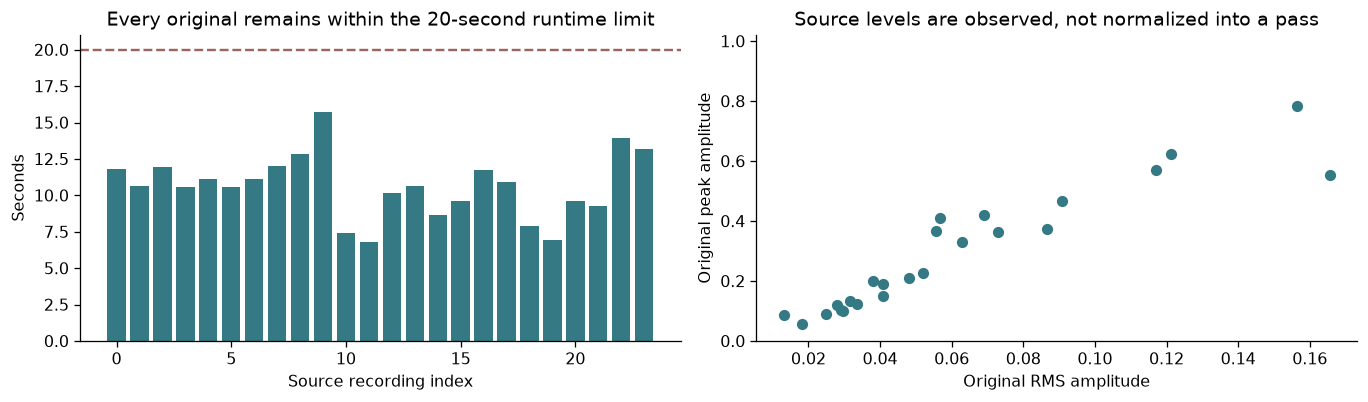

In [6]:
# DATA-CLEAN-3
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].bar(np.arange(len(SOURCES)), SOURCES.duration_seconds, color=COLORS['output'])
axes[0].set(xlabel='Source recording index', ylabel='Seconds', title='Every original remains within the 20-second runtime limit')
axes[0].axhline(20, linestyle='--', color=COLORS['input'])
axes[1].scatter(SOURCES.RMS, SOURCES.peak, color=COLORS['output'])
axes[1].set(xlabel='Original RMS amplitude', ylabel='Original peak amplitude', title='Source levels are observed, not normalized into a pass')
axes[1].set_ylim(0, 1.02)
plt.tight_layout()
plt.show()

 Working copies preserve full duration at 22,050 Hz and PCM24. Levels are observed rather than normalized into a pass. A technical working copy does not automatically supply eligible controlled-shift labels.

<a id="DATA-SPLITS"></a>
### `DATA-SPLITS` · Singer-separated splits and all exclusions

In [7]:
#  DATA-SPLITS
groups = {s: set(SOURCES.loc[SOURCES.split == s, 'singer']) for s in SPLITS}
coverage = []
excluded_rows = []
for split in SPLITS:
    pairs = PAIRS[split]
    valid = [p for p in pairs if 'excluded' not in p]
    
    keys = [(p['source']['sha256'], p['cents']) for p in pairs]
   
    coverage.append(dict(split=split, assigned_recordings=len(SOURCE_RECORDS[split]), assigned_singers=len(groups[split]), recordings_with_valid_pairs=len({p['source']['sha256'] for p in valid}), singers_with_valid_pairs=len({p['source']['singer_id'] for p in valid}), signed_attempts=len(pairs), audited_pairs=len(valid), excluded_attempts=len(pairs) - len(valid)))
    for reason, count in Counter((p['excluded'] for p in pairs if 'excluded' in p)).items():
        excluded_rows.append(dict(split=split, reason=reason, attempts=count))
COVERAGE = pd.DataFrame(coverage).set_index('split').loc[SPLITS]
show(COVERAGE)

,assigned_recordings,assigned_singers,recordings_with_valid_pairs,singers_with_valid_pairs,signed_attempts,audited_pairs,excluded_attempts
split,,,,,,,
train,16,8,13,7,64,43,21
calibration,4,2,3,2,16,10,6
pilot_evaluation,4,2,2,1,16,4,12


<a id="DATA-SPLITS-2"></a>
#### Inspect the result

In [8]:
# DATA-SPLITS-2
show(pd.DataFrame(excluded_rows))

,split,reason,attempts
0,train,CONTROLLED_INTERVENTION_AUDIT_FAILED,9
1,train,NO_OWN_AUDIO_STABLE_RUN_WITH_CONTEXT_FOR_096_SECOND_INTERVENTION,12
2,calibration,CONTROLLED_INTERVENTION_AUDIT_FAILED,6
3,pilot_evaluation,NO_OWN_AUDIO_STABLE_RUN_WITH_CONTEXT_FOR_096_SECOND_INTERVENTION,4
4,pilot_evaluation,CONTROLLED_INTERVENTION_AUDIT_FAILED,8


<a id="DATA-SPLITS-4"></a>
#### Visualize the result

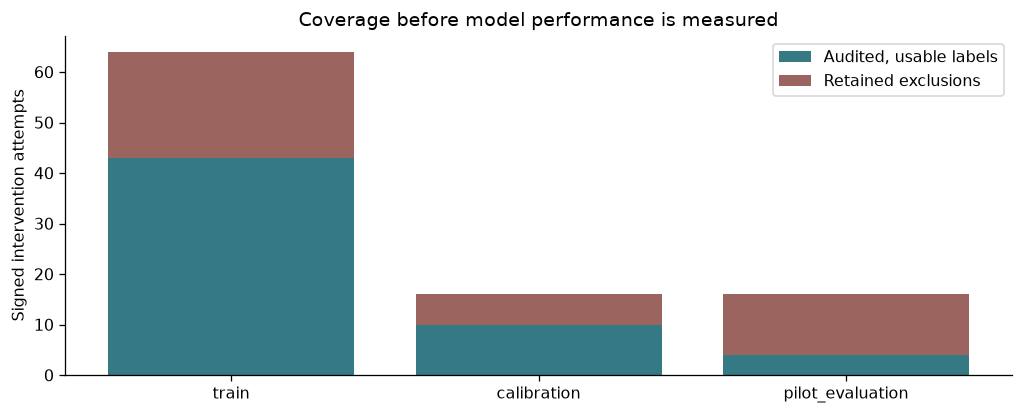

In [9]:
#  DATA-SPLITS-4
fig, ax = plt.subplots(figsize=(9, 3.7))
x = np.arange(3)
ax.bar(x, COVERAGE.audited_pairs, label='Audited, usable labels', color=COLORS['output'])
ax.bar(x, COVERAGE.excluded_attempts, bottom=COVERAGE.audited_pairs, label='Retained exclusions', color=COLORS['input'])
ax.set_xticks(x, SPLITS)
ax.set(ylabel='Signed intervention attempts', title='Coverage before model performance is measured')
ax.legend()
plt.tight_layout()
plt.show()

Read assigned singers alongside singers with valid pairs. Exclusions remain in attempted coverage. Training labels come from 43 pairs, 13 originals and 7 singers; the pilot has four valid pairs from one singer.

<a id="DATA-EXAMPLE"></a>
### Load one audited training example

The feature and spectrogram outputs below use this existing training recording. Loading it does not create new interventions or use evaluation data.

In [10]:
# Code block: DATA-EXAMPLE
TRAIN_PAIR = next(p for p in PAIRS['train'] if 'excluded' not in p)
with np.load(TRAIN_PAIR['target_path']) as z:
    train_times = z['times']
TRAIN_A, sr = sf.read(TRAIN_PAIR['path_A'], dtype='float32')
train_pitch_a = fine_pitch(TRAIN_A, sr, train_times)
show(pd.DataFrame([dict(singer=TRAIN_PAIR['source']['singer_id'],
    vowel=TRAIN_PAIR['source']['vowel'], example_shift_cents=TRAIN_PAIR['cents'])]))

C:\Users\lnipu\Projects\Music Rp\RP\J26-DS-339\experiments\bpdr_input\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,singer,vowel,example_shift_cents
0,female1,a,20.0000


<a id="DATA-FEATURES"></a>
### `DATA-FEATURES` · Every ordered feature and actual feature function

In [11]:
# Code block: DATA-FEATURES
from bpdr_input.modeling.local_context_pilot import context_features, WINDOW_FRAMES
from bpdr_input.repair.model_runtime import runtime_views
with np.load(Path(TRAIN_PAIR['path_A']).parent / 'original_features.npz') as z:
    TRAIN_FEATURES = {k: z[k] for k in z.files}
raw_views, raw_reliable, raw_protected, adapter_metadata = runtime_views(TRAIN_FEATURES, train_pitch_a)
feature_rows = [('phrase_relative_pitch', 'cents / 1200, clipped', 'Position relative to this phrase median'), ('chromatic_residual', 'cents / 30', 'Deviation from this performance circular semitone grid'), ('residual_sine', 'unitless', 'Circular encoding of the residual'), ('residual_cosine', 'unitless', 'Circular encoding without a discontinuity at wraparound'), ('pitch_confidence', '0-1', 'Frozen tracker confidence; not probability of singing correctly'), ('voiced', '0 or 1', 'A reliable performed pitch is present'), ('pitch_delta', 'cents / 30, clipped', 'Neighboring fine-pitch change'), ('relative_energy', 'dB / 20, clipped', 'Energy relative to this phrase'), ('onset', '0-1', 'Measured onset score')]
for width in WINDOW_FRAMES:
    seconds = width * 0.02
    feature_rows.extend([(f'pitch_minus_median_{width}', 'cents / 30, clipped', f'Pitch deviation from {seconds:.2f}s local median'), (f'residual_minus_median_{width}', 'cents / 30', f'Circular residual deviation in {seconds:.2f}s'), (f'residual_mean_{width}', 'cents / 30', f'Mean local residual in {seconds:.2f}s'), (f'residual_spread_{width}', 'cents / 30', f'Local residual variation in {seconds:.2f}s'), (f'voiced_coverage_{width}', '0-1', f'Fraction of voiced observations in {seconds:.2f}s')])
feature_rows += [('endpoint_contour_residual', 'cents / 30, clipped', 'Difference from an own-audio endpoint contour'), ('absolute_pitch_delta', 'abs(cents) / 100, clipped', 'Magnitude of neighboring pitch movement')]
FEATURE_TABLE = pd.DataFrame(feature_rows, columns=['feature', 'scale', 'meaning'])
FEATURE_TABLE.index.name = 'model_column'
FEATURE_NAMES = FEATURE_TABLE.feature.tolist()
X_EXAMPLE = context_features(raw_views[0], include_boundary=False)
for alternative in raw_views[1:]:
    np.testing.assert_array_equal(X_EXAMPLE, context_features(alternative, include_boundary=False))
show(FEATURE_TABLE)

,feature,scale,meaning
model_column,,,
0,phrase_relative_pitch,"cents / 1200, clipped",Position relative to this phrase median
1,chromatic_residual,cents / 30,Deviation from this performance circular semitone grid
2,residual_sine,unitless,Circular encoding of the residual
3,residual_cosine,unitless,Circular encoding without a discontinuity at wraparound
4,pitch_confidence,0-1,Frozen tracker confidence; not probability of singing correctly
5,voiced,0 or 1,A reliable performed pitch is present
6,pitch_delta,"cents / 30, clipped",Neighboring fine-pitch change
7,relative_energy,"dB / 20, clipped",Energy relative to this phrase
8,onset,0-1,Measured onset score


<a id="DATA-FEATURES-2"></a>
#### Inspect the result

In [12]:
#  DATA-FEATURES-2
show(pd.DataFrame(X_EXAMPLE[:5], columns=FEATURE_NAMES)[['phrase_relative_pitch', 'chromatic_residual', 'pitch_confidence', 'voiced', 'pitch_delta']].round(4))

,phrase_relative_pitch,chromatic_residual,pitch_confidence,voiced,pitch_delta
0,-0.3876,1.0096,0.1033,0.0000,0.0000
1,-0.3876,1.0096,0.0964,0.0000,0.0000
2,-0.3876,1.0096,0.0981,0.0000,0.0000
3,-0.3876,1.0096,0.0966,0.0000,0.0000
4,-0.3876,1.0096,0.0909,0.0000,0.0000


<a id="DATA-SPECTROGRAM"></a>
### `DATA-SPECTROGRAM` · Real measured waveform, spectrum, F0, confidence and boundaries

In [13]:
# DATA-SPECTROGRAM
with np.load(Path(TRAIN_PAIR['path_A']).parent / 'original_features.npz') as z:
    acoustic = {k: z[k] for k in z.files}

<a id="DATA-SPECTROGRAM-2"></a>
#### Visualize the result

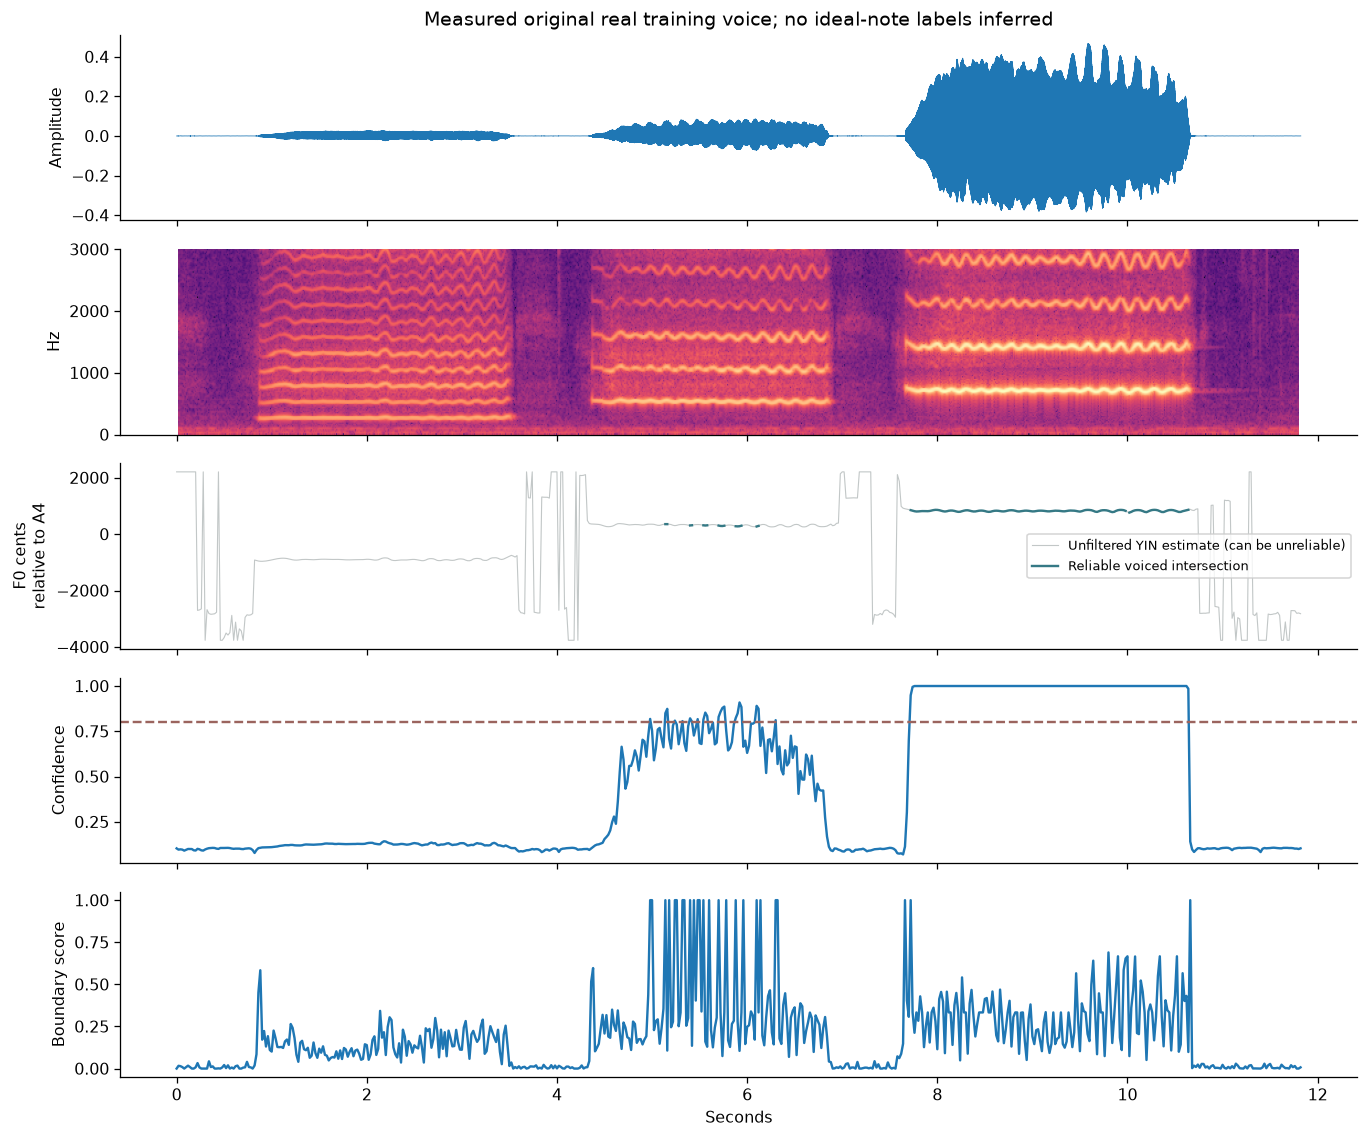

In [14]:
#  DATA-SPECTROGRAM-2
fig, axes = plt.subplots(5, 1, figsize=(12, 10), sharex=True)
axes[0].plot(np.arange(len(TRAIN_A)) / 22050, TRAIN_A, linewidth=0.5)
axes[0].set_ylabel('Amplitude')
axes[1].specgram(TRAIN_A, NFFT=1024, Fs=22050, noverlap=768, cmap='magma')
axes[1].set_ylim(0, 3000)
axes[1].set_ylabel('Hz')
axes[2].plot(train_times, train_pitch_a, color='#c2c7c7', linewidth=0.7, label='Unfiltered YIN estimate (can be unreliable)')
axes[2].plot(train_times, np.where(raw_reliable, train_pitch_a, np.nan), color=COLORS['output'], label='Reliable voiced intersection')
axes[2].set_ylabel('F0 cents\nrelative to A4')
axes[2].legend(fontsize=8)
axes[3].plot(acoustic['times_seconds'], acoustic['confidence'])
axes[3].axhline(0.8, linestyle='--', color=COLORS['input'])
axes[3].set_ylabel('Confidence')
axes[4].plot(acoustic['times_seconds'], acoustic['provisional_boundary_score'])
axes[4].set(ylabel='Boundary score', xlabel='Seconds')
axes[0].set_title('Measured original real training voice; no ideal-note labels inferred')
plt.tight_layout()
plt.show()

These are measurements of one real original: waveform, spectrum, pitch, confidence and boundary score. Reliable pitch is masked; neither confidence nor a pitch contour identifies the intended melody.